In [1]:
import pystac_client
import planetary_computer
import xarray as xr


In [2]:
catalog = pystac_client.Client.open(
    "https://planetarycomputer.microsoft.com/api/stac/v1/",
    modifier=planetary_computer.sign_inplace, # Automatically signs URLs for access
)
search = catalog.search(collections=["era5-pds"], datetime=["1980-01", "1982-01"])
items = search.item_collection()

len(items)

50

In [3]:
item = items[0]
item.assets

{'precipitation_amount_1hour_Accumulation': <Asset href=abfs://era5/ERA5/1982/01/precipitation_amount_1hour_Accumulation.zarr>,
 'air_temperature_at_2_metres_1hour_Maximum': <Asset href=abfs://era5/ERA5/1982/01/air_temperature_at_2_metres_1hour_Maximum.zarr>,
 'air_temperature_at_2_metres_1hour_Minimum': <Asset href=abfs://era5/ERA5/1982/01/air_temperature_at_2_metres_1hour_Minimum.zarr>,
 'integral_wrt_time_of_surface_direct_downwelling_shortwave_flux_in_air_1hour_Accumulation': <Asset href=abfs://era5/ERA5/1982/01/integral_wrt_time_of_surface_direct_downwelling_shortwave_flux_in_air_1hour_Accumulation.zarr>}

In [ ]:
zarr_asset = item.assets["integral_wrt_time_of_surface_direct_downwelling_shortwave_flux_in_air_1hour_Accumulation"]

xarray_open_kwargs = zarr_asset.extra_fields.get("xarray:open_kwargs", {})

ds = xr.open_zarr(
    zarr_asset.href,
    consolidated=xarray_open_kwargs.get("consolidated", False),
    chunks=xarray_open_kwargs.get("chunks", {}),
    storage_options=xarray_open_kwargs.get("storage_options", {}),
)


In [5]:
ds


<xarray.Dataset> Size: 3GB
Dimensions:                                  (time: 744, lat: 721, lon: 1440,
                                              nv: 2)
Coordinates:
  * time                                     (time) datetime64[ns] 6kB 1982-0...
  * lat                                      (lat) float32 3kB 90.0 ... -90.0
  * lon                                      (lon) float32 6kB 0.0 ... 359.8
Dimensions without coordinates: nv
Data variables:
    precipitation_amount_1hour_Accumulation  (time, lat, lon) float32 3GB dask.array<chunksize=(372, 150, 150), meta=np.ndarray>
    time1_bounds                             (time, nv) datetime64[ns] 12kB dask.array<chunksize=(744, 2), meta=np.ndarray>
Attributes:
    institution:  ECMWF
    source:       Reanalysis
    title:        ERA5 forecasts

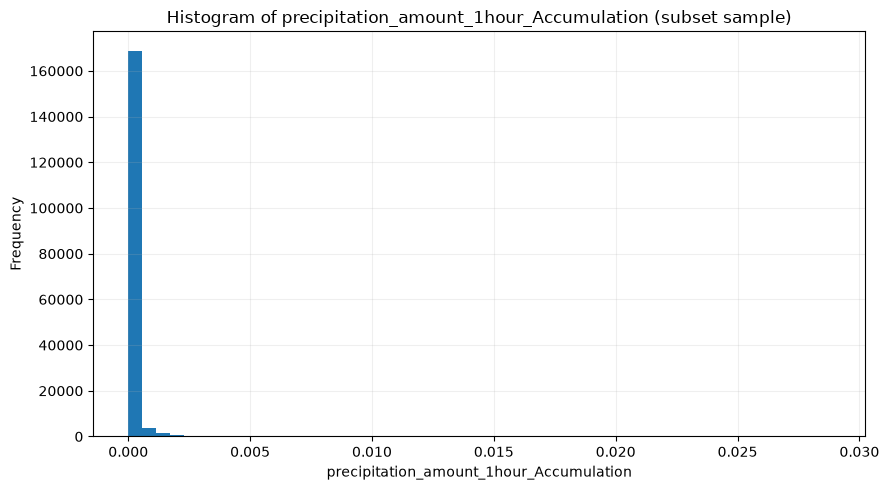

In [6]:
import matplotlib.pyplot as plt
import numpy as np

# Use the first data variable (precipitation in this dataset)
var_name = list(ds.data_vars)[0]
da = ds[var_name]

# Detect common spatial dimension names
lat_dim = "latitude" if "latitude" in da.dims else "lat"
lon_dim = "longitude" if "longitude" in da.dims else "lon"

# Subset sample (small in-memory slice for fast histogram)
sample = da.isel(
    time=slice(0, min(24, da.sizes.get("time", 1))),
    **{lat_dim: slice(None, None, 12), lon_dim: slice(None, None, 12)},
).compute()

values = sample.values.ravel()
values = values[~np.isnan(values)]

plt.figure(figsize=(9, 5))
plt.hist(values, bins=50)
plt.title(f"Histogram of {var_name} (subset sample)")
plt.xlabel(var_name)
plt.ylabel("Frequency")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()


In [7]:
import socket
import threading

import numpy as np
import pandas as pd
import plotly.graph_objects as go
from dash import Dash, Input, Output, State, dcc, html

# Pick precipitation variable and normalize common dimension names
var_name = list(ds.data_vars)[0]
da = ds[var_name]
lat_dim = "latitude" if "latitude" in da.dims else "lat"
lon_dim = "longitude" if "longitude" in da.dims else "lon"

# Use a moderate subset for responsiveness while preserving map detail
hour_count = min(72, da.sizes.get("time", 1))
precip_subset = da.isel(
    time=slice(0, hour_count),
    **{lat_dim: slice(None, None, 2), lon_dim: slice(None, None, 2)},
).compute()

times = pd.to_datetime(precip_subset["time"].values)
lats = precip_subset[lat_dim].values
lons = precip_subset[lon_dim].values
values = np.asarray(precip_subset.values)

# Ensure latitude increases upward on the plot (north at top)
if lats[0] > lats[-1]:
    lats = lats[::-1]
    values = values[:, ::-1, :]

# Robust color scaling improves contrast for low-vs-high precipitation
positive_values = values[values > 0]
if positive_values.size:
    zmin = float(np.percentile(positive_values, 5))
    zmax = float(np.percentile(positive_values, 99))
else:
    zmin, zmax = float(np.nanmin(values)), float(np.nanmax(values))

if not np.isfinite(zmin) or not np.isfinite(zmax) or zmin >= zmax:
    zmin, zmax = 0.0, 1.0


def _precip_figure(idx: int) -> go.Figure:
    z = values[idx]

    fig = go.Figure()
    fig.add_trace(
        go.Heatmap(
            z=z,
            x=lons,
            y=lats,
            zsmooth="best",
            colorscale="Blues",
            zmin=zmin,
            zmax=zmax,
            colorbar={"title": var_name},
            hovertemplate=(
                "Lon: %{x:.2f}<br>"
                "Lat: %{y:.2f}<br>"
                f"{var_name}: "
                "%{z:.3f}<extra></extra>"
            ),
        )
    )

    # Light contour lines make rain bands easier to read than raw pixels alone
    fig.add_trace(
        go.Contour(
            z=z,
            x=lons,
            y=lats,
            contours={"showlines": True, "showlabels": False, "coloring": "none"},
            line={"color": "rgba(0,0,0,0.28)", "width": 0.7},
            showscale=False,
            hoverinfo="skip",
        )
    )

    fig.update_layout(
        title=f"Hourly precipitation: {times[idx]}",
        margin={"l": 50, "r": 20, "t": 60, "b": 50},
        height=700,
        template="plotly_white",
    )

    fig.update_xaxes(
        title=lon_dim,
        showgrid=True,
        gridcolor="rgba(70,70,70,0.18)",
        zeroline=False,
    )
    fig.update_yaxes(
        title=lat_dim,
        showgrid=True,
        gridcolor="rgba(70,70,70,0.18)",
        zeroline=False,
        scaleanchor="x",
        scaleratio=1,
    )

    return fig


def _find_free_port() -> int:
    with socket.socket(socket.AF_INET, socket.SOCK_STREAM) as s:
        s.bind(("127.0.0.1", 0))
        return s.getsockname()[1]


if "precip_dash_thread" in globals() and precip_dash_thread.is_alive():
    print(f"Dash app already running at http://127.0.0.1:{precip_dash_port}")
else:
    precip_dash_port = _find_free_port()
    app = Dash(__name__)

    app.layout = html.Div(
        [
            html.H3("ERA5 Precipitation - Hourly Animated Map"),
            dcc.Graph(id="precip-map", figure=_precip_figure(0)),
            dcc.Slider(
                id="hour-slider",
                min=0,
                max=hour_count - 1,
                step=1,
                value=0,
                tooltip={"always_visible": True},
            ),
            dcc.Interval(id="hour-ticker", interval=1200, n_intervals=0),
            html.Div(id="timestamp-label", style={"marginTop": "10px", "fontWeight": "bold"}),
        ],
        style={"maxWidth": "1100px", "margin": "0 auto", "fontFamily": "sans-serif"},
    )

    @app.callback(Output("hour-slider", "value"), Input("hour-ticker", "n_intervals"), State("hour-slider", "value"))
    def _advance_slider(_n, current):
        if current is None:
            return 0
        return (current + 1) % hour_count

    @app.callback(
        Output("precip-map", "figure"),
        Output("timestamp-label", "children"),
        Input("hour-slider", "value"),
    )
    def _update_map(hour_idx):
        idx = int(hour_idx or 0)
        ts = str(times[idx])
        return _precip_figure(idx), f"Frame time: {ts}"

    def _run_dash():
        app.run(host="127.0.0.1", port=precip_dash_port, debug=False, use_reloader=False)

    precip_dash_thread = threading.Thread(target=_run_dash, daemon=True)
    precip_dash_thread.start()

    print(f"Dash app running at http://127.0.0.1:{precip_dash_port}")
    print("Open that URL in your browser to see the animated hourly precipitation map.")

Dash app running at http://127.0.0.1:41819
Open that URL in your browser to see the animated hourly precipitation map.


In [8]:
import socket
import threading

import numpy as np
import pandas as pd
import plotly.graph_objects as go
from dash import Dash, Input, Output, State, dcc, html

# List all available data variables in the dataset
print("Available variables in ERA5 dataset:")
for var in ds.data_vars:
    print(f"  - {var}: {ds[var].dims}, shape={ds[var].shape}")

# Select a flux variable (e.g., latent_heat_flux, sensible_heat_flux, surface_downwelling_shortwave_radiation_flux)
# Adjust based on what's available in your dataset
flux_vars = [v for v in ds.data_vars if 'flux' in v.lower() or 'radiation' in v.lower()]
print(f"\nFlux/radiation variables found: {flux_vars}")

if flux_vars:
    flux_var_name = flux_vars[0]  # Use first flux variable found
    print(f"\nPlotting: {flux_var_name}")
    
    flux_da = ds[flux_var_name]
    flux_lat_dim = "latitude" if "latitude" in flux_da.dims else "lat"
    flux_lon_dim = "longitude" if "longitude" in flux_da.dims else "lon"
    
    # Subset for responsiveness
    flux_hour_count = min(72, flux_da.sizes.get("time", 1))
    flux_subset = flux_da.isel(
        time=slice(0, flux_hour_count),
        **{flux_lat_dim: slice(None, None, 2), flux_lon_dim: slice(None, None, 2)},
    ).compute()
    
    flux_times = pd.to_datetime(flux_subset["time"].values)
    flux_lats = flux_subset[flux_lat_dim].values
    flux_lons = flux_subset[flux_lon_dim].values
    flux_values = np.asarray(flux_subset.values)
    
    # Ensure latitude increases upward
    if flux_lats[0] > flux_lats[-1]:
        flux_lats = flux_lats[::-1]
        flux_values = flux_values[:, ::-1, :]
    
    # Robust color scaling
    flux_positive = flux_values[flux_values > 0]
    if flux_positive.size:
        flux_zmin = float(np.percentile(flux_positive, 5))
        flux_zmax = float(np.percentile(flux_positive, 95))
    else:
        flux_zmin = float(np.nanmin(flux_values))
        flux_zmax = float(np.nanmax(flux_values))
    
    if not np.isfinite(flux_zmin) or not np.isfinite(flux_zmax) or flux_zmin >= flux_zmax:
        flux_zmin, flux_zmax = 0.0, 1.0
    
    def _flux_figure(idx: int) -> go.Figure:
        z = flux_values[idx]
        
        fig = go.Figure()
        fig.add_trace(
            go.Heatmap(
                z=z,
                x=flux_lons,
                y=flux_lats,
                zsmooth="best",
                colorscale="Viridis",
                zmin=flux_zmin,
                zmax=flux_zmax,
                colorbar={"title": flux_var_name},
                hovertemplate=(
                    "Lon: %{x:.2f}<br>"
                    "Lat: %{y:.2f}<br>"
                    f"{flux_var_name}: "
                    "%{z:.2f}<extra></extra>"
                ),
            )
        )
        
        # Contours for pattern clarity
        fig.add_trace(
            go.Contour(
                z=z,
                x=flux_lons,
                y=flux_lats,
                contours={"showlines": True, "showlabels": False, "coloring": "none"},
                line={"color": "rgba(0,0,0,0.28)", "width": 0.7},
                showscale=False,
                hoverinfo="skip",
            )
        )
        
        fig.update_layout(
            title=f"{flux_var_name}: {flux_times[idx]}",
            margin={"l": 50, "r": 20, "t": 60, "b": 50},
            height=700,
            template="plotly_white",
        )
        
        fig.update_xaxes(
            title=flux_lon_dim,
            showgrid=True,
            gridcolor="rgba(70,70,70,0.18)",
        )
        fig.update_yaxes(
            title=flux_lat_dim,
            showgrid=True,
            gridcolor="rgba(70,70,70,0.18)",
            scaleanchor="x",
            scaleratio=1,
        )
        
        return fig
    
    def _find_free_port() -> int:
        with socket.socket(socket.AF_INET, socket.SOCK_STREAM) as s:
            s.bind(("127.0.0.1", 0))
            return s.getsockname()[1]
    
    if "flux_dash_thread" in globals() and flux_dash_thread.is_alive():
        print(f"Flux Dash app already running at http://127.0.0.1:{flux_dash_port}")
    else:
        flux_dash_port = _find_free_port()
        flux_app = Dash(__name__, suppress_callback_exceptions=True)
        
        flux_app.layout = html.Div(
            [
                html.H3(f"ERA5 {flux_var_name} - Hourly Animated Map"),
                dcc.Graph(id="flux-map", figure=_flux_figure(0)),
                dcc.Slider(
                    id="flux-hour-slider",
                    min=0,
                    max=flux_hour_count - 1,
                    step=1,
                    value=0,
                    tooltip={"always_visible": True},
                ),
                dcc.Interval(id="flux-hour-ticker", interval=1200, n_intervals=0),
                html.Div(id="flux-timestamp-label", style={"marginTop": "10px", "fontWeight": "bold"}),
            ],
            style={"maxWidth": "1100px", "margin": "0 auto", "fontFamily": "sans-serif"},
        )
        
        @flux_app.callback(Output("flux-hour-slider", "value"), Input("flux-hour-ticker", "n_intervals"), State("flux-hour-slider", "value"))
        def _advance_flux_slider(_n, current):
            if current is None:
                return 0
            return (current + 1) % flux_hour_count
        
        @flux_app.callback(
            Output("flux-map", "figure"),
            Output("flux-timestamp-label", "children"),
            Input("flux-hour-slider", "value"),
        )
        def _update_flux_map(hour_idx):
            idx = int(hour_idx or 0)
            ts = str(flux_times[idx])
            return _flux_figure(idx), f"Frame time: {ts}"
        
        def _run_flux_dash():
            flux_app.run(host="127.0.0.1", port=flux_dash_port, debug=False, use_reloader=False)
        
        flux_dash_thread = threading.Thread(target=_run_flux_dash, daemon=True)
        flux_dash_thread.start()
        
        print(f"Flux Dash app running at http://127.0.0.1:{flux_dash_port}")
        print("Open that URL in your browser to see the animated flux map.")
else:
    print("No flux/radiation variables found in dataset.")

Available variables in ERA5 dataset:
  - precipitation_amount_1hour_Accumulation: ('time', 'lat', 'lon'), shape=(744, 721, 1440)
  - time1_bounds: ('time', 'nv'), shape=(744, 2)

Flux/radiation variables found: []
No flux/radiation variables found in dataset.
